# T1-2: Solid Body Rotation (2D)

## Verification Study — Tier 1 / Trivial Trajectories

**Field:** $u = -\Omega\,y$, $v = \Omega\,x$

**Analytical trajectory:**
$$x(t) = R\cos(\Omega t + \varphi_0), \quad y(t) = R\sin(\Omega t + \varphi_0), \quad R = \sqrt{x_0^2 + y_0^2}$$

**Purpose:** Verifies angular momentum conservation; isolates time integrator on a closed orbit

**Expected convergence:** Order $p$ (integrator order) in $\Delta t$; interpolation exact for linear fields on node-centered grids. The ODE system for this field has purely imaginary eigenvalues for which the first order euler method is unstable. Because of this, we demonstrate this instability behavior of the first order euler time integrator, and do not expect convergence for that method.

**Notes:** Use to determine baseline ODE order; check period error over many orbits

---

### Approach

We construct a Delaunay triangulation over a square domain centered at the origin and define
a solid-body rotation velocity field $\mathbf{u} = (-\Omega y,\; \Omega x)$. Because this field
is *linear* in the spatial coordinates:

- **Node-centered (barycentric linear interpolation):** the interpolant reproduces the field
  exactly, so all error comes from the time integrator → expect order $p$ convergence in $\Delta t$.
- **Face-centered (piecewise constant interpolation):** the interpolant introduces spatial
  truncation error that does *not* vanish with $\Delta t$ → expect a *floor* in the error
  set by the mesh spacing.

We run a $\Delta t$ convergence study on the node-centered configuration and verify the
expected slopes. We also check period (phase) error after many orbits.

In [1]:
import math
import os
import shutil

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import uxarray as ux
import xarray as xr

import parcels
from parcels._core.particle import get_default_particle

# Parcels' default Particle stores positions in float32 (~1e-6 deg resolution);
# use float64 positions so the 1e-10 tolerance below is meaningful.
Particle64 = get_default_particle(np.float64)

## 1. Parameters

In [2]:
# Domain (centered at origin so rotation center = (0, 0))
NX = 40  # Grid points per side (finer than T1-1 to resolve linear field)
HALF = 5.0
LON_MIN, LON_MAX = -HALF, HALF
LAT_MIN, LAT_MAX = -HALF, HALF

# Rotation rate
OMEGA = 2.0 * np.pi / 3600.0  # one full revolution in 3600 s

# Time — run for 5 full orbits to expose period/phase drift
N_ORBITS = 1
PERIOD = 2.0 * np.pi / OMEGA  # 3600 s
T_TOTAL_S = N_ORBITS * PERIOD  # 18000 s
T_TOTAL = np.timedelta64(int(T_TOTAL_S), "s")
DT_BASE = np.timedelta64(30, "s")  # baseline timestep

# Single-snapshot velocity (steady field)
N_TIMESTEPS = 1
TIME = xr.date_range("2000-01-01", periods=N_TIMESTEPS, freq="2h")

# Particle initial positions — ring at various radii
RADII = [1.0, 2.0, 3.0]
ANGLES_PER_RING = 4
p_lon0, p_lat0 = [], []
for R in RADII:
    for k in range(ANGLES_PER_RING):
        theta = 2.0 * np.pi * k / ANGLES_PER_RING
        p_lon0.append(R * np.cos(theta))
        p_lat0.append(R * np.sin(theta))
p_lon0 = np.array(p_lon0, dtype=np.float64)
p_lat0 = np.array(p_lat0, dtype=np.float64)
N_PARTICLES = len(p_lon0)

print(f"Ω = {OMEGA:.6e} rad/s, period = {PERIOD:.1f} s")
print(f"Total runtime = {T_TOTAL_S:.0f} s  ({N_ORBITS} orbits)")
print(f"{N_PARTICLES} particles at radii {RADII}")

Ω = 1.745329e-03 rad/s, period = 3600.0 s
Total runtime = 3600 s  (1 orbits)
12 particles at radii [1.0, 2.0, 3.0]


## 2. Build Unstructured Grid

In [3]:
lon, lat = np.meshgrid(
    np.linspace(LON_MIN, LON_MAX, NX, dtype=np.float64),
    np.linspace(LAT_MIN, LAT_MAX, NX, dtype=np.float64),
)
lon_flat = lon.ravel()
lat_flat = lat.ravel()

# Boundary mask for Delaunay
mask = (
    np.isclose(lon_flat, LON_MIN)
    | np.isclose(lon_flat, LON_MAX)
    | np.isclose(lat_flat, LAT_MIN)
    | np.isclose(lat_flat, LAT_MAX)
)
boundary_points = np.flatnonzero(mask)

uxgrid = ux.Grid.from_points(
    (lon_flat, lat_flat),
    method="regional_delaunay",
    boundary_points=boundary_points,
)
uxgrid.attrs["Conventions"] = "UGRID-1.0"

print(f"Grid: {uxgrid.n_node} nodes, {uxgrid.n_face} faces")

Grid: 1600 nodes, 3039 faces


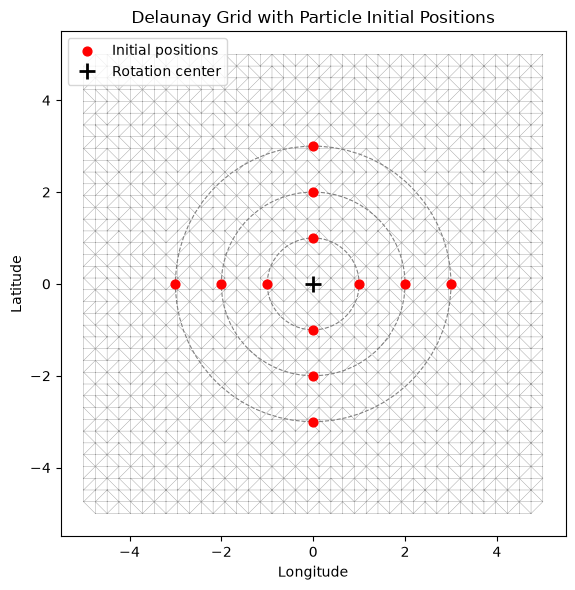

In [4]:
# Visualize grid and initial particle positions
fig, ax = plt.subplots(figsize=(6, 6))
triang = mtri.Triangulation(
    uxgrid.node_lon.values, uxgrid.node_lat.values,
    triangles=uxgrid.face_node_connectivity.values,
)
ax.triplot(triang, "k-", lw=0.3, alpha=0.4)
for R in RADII:
    circle = plt.Circle((0, 0), R, fill=False, ls="--", color="gray", lw=0.8)
    ax.add_patch(circle)
ax.scatter(p_lon0, p_lat0, c="red", s=40, zorder=5, label="Initial positions")
ax.plot(0, 0, "k+", ms=12, mew=2, label="Rotation center")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Delaunay Grid with Particle Initial Positions")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 3. Define Velocity Fields

Solid-body rotation about the origin:
$$u = -\Omega\,y, \quad v = \Omega\,x$$

This is a linear field, so barycentric (node-centered) interpolation reproduces it exactly.

In [5]:
# Vertical coordinates (single layer)
zf = np.array([0.0, 1.0], dtype=np.float64)
zc = np.array([0.5], dtype=np.float64)


def make_face_centered_dataset(uxgrid, omega):
    """Velocity on face centers: u = -omega*y_face, v = omega*x_face."""
    face_lon = uxgrid.face_lon.values  # (n_face,)
    face_lat = uxgrid.face_lat.values

    u_vals = -omega * face_lat
    v_vals = omega * face_lon

    U = np.broadcast_to(u_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_face)).copy()
    V = np.broadcast_to(v_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_face)).copy()
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity (solid-body rotation)"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity (solid-body rotation)"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


def make_node_centered_dataset(uxgrid, omega):
    """Velocity on corner nodes: u = -omega*y_node, v = omega*x_node."""
    node_lon = uxgrid.node_lon.values  # (n_node,)
    node_lat = uxgrid.node_lat.values

    u_vals = -omega * node_lat
    v_vals = omega * node_lon

    U = np.broadcast_to(u_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_node)).copy()
    V = np.broadcast_to(v_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_node)).copy()
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity (solid-body rotation)"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity (solid-body rotation)"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


ds_face = make_face_centered_dataset(uxgrid, OMEGA)
ds_node = make_node_centered_dataset(uxgrid, OMEGA)

print("Face-centered dataset:")
print(ds_face)
print()
print("Node-centered dataset:")
print(ds_node)

Face-centered dataset:
<xarray.UxDataset> Size: 74kB
Dimensions:  (time: 1, zc: 1, n_face: 3039, zf: 2, n_node: 1600)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 8B 0.5
  * zf       (zf) float64 16B 0.0 1.0
Dimensions without coordinates: n_face, n_node
Data variables:
    U        (time, zc, n_face) float64 24kB 0.0008205 0.0009696 ... 0.004848
    V        (time, zc, n_face) float64 24kB -0.008577 -0.008428 ... 0.002611
    W        (time, zf, n_node) float64 26kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0

Node-centered dataset:
<xarray.UxDataset> Size: 51kB
Dimensions:  (time: 1, zc: 1, n_node: 1600, zf: 2)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 8B 0.5
  * zf       (zf) float64 16B 0.0 1.0
Dimensions without coordinates: n_node
Data variables:
    U        (time, zc, n_node) float64 13kB 0.008727 0.008727 ... -0.008727
    V        (time, zc, n_node) float64 13kB -0.008727 -0.008279 ... 0.008727
 

## 4. Analytical Solution

For solid-body rotation $\mathbf{u} = (-\Omega y,\; \Omega x)$, a particle starting at
$(x_0, y_0)$ follows:

$$x(t) = R\cos(\Omega t + \varphi_0), \quad y(t) = R\sin(\Omega t + \varphi_0)$$

where $R = \sqrt{x_0^2 + y_0^2}$ and $\varphi_0 = \mathrm{atan2}(y_0, x_0)$.

Key invariants:
- **Radius** is conserved: $|\mathbf{x}(t)| = R$ for all $t$
- **Angular velocity** is constant: $\dot{\varphi} = \Omega$

In [6]:
def analytical_position(lon0, lat0, omega, dt_seconds):
    """Exact particle position after dt_seconds of solid-body rotation."""
    R = np.sqrt(lon0**2 + lat0**2)
    phi0 = np.arctan2(lat0, lon0)
    phi = phi0 + omega * dt_seconds
    return R * np.cos(phi), R * np.sin(phi)


def analytical_trajectory(lon0, lat0, omega, t_array):
    """Exact trajectory at an array of times (seconds)."""
    R = np.sqrt(lon0**2 + lat0**2)
    phi0 = np.arctan2(lat0, lon0)
    phi = phi0 + omega * t_array
    return R * np.cos(phi), R * np.sin(phi)

## 5. Run Advection: All Interpolator / Time Integrator Combinations

| Data Location | Interpolator | Description |
|---|---|---|
| Face-centered | `UxConstantFaceConstantZC` | Piecewise constant (face), constant vertical |
| Node-centered | `UxLinearNodeConstantZC` | Barycentric linear (node), constant vertical |

Time integrators:
- **Euler** (`AdvectionEE`) — order 1
- **Runge-Kutta 4** (`AdvectionRK4`) — order 4

We use the baseline $\Delta t$ for this initial comparison.

In [7]:
time_integrators = {
    "EE": parcels.kernels.AdvectionEE,
    "RK4": parcels.kernels.AdvectionRK4,
}

field_configs = {
    "face-centered": ds_face,
    "node-centered": ds_node,
}

# Evaluate error at the final time
# Account for the last output step: the final particle position is at T_TOTAL
t_eval = T_TOTAL_S

results = []
output_files = {}

for field_label, ds in field_configs.items():
    fieldset = parcels.FieldSet.from_ugrid_conventions(ds, mesh="flat")

    for integrator_label, integrator in time_integrators.items():
        out_name = f"T1_2_{field_label}_{integrator_label}.parquet"

        pset = parcels.ParticleSet(
            fieldset,
            pclass=Particle64,
            x=p_lon0.copy(),
            y=p_lat0.copy(),
        )

        pfile = parcels.ParticleFile(path=out_name, outputdt=DT_BASE, mode="w")

        pset.execute(
            integrator,
            runtime=T_TOTAL,
            dt=DT_BASE,
            output_file=pfile,
            verbose_progress=False,
        )

        lon_exact, lat_exact = analytical_position(p_lon0, p_lat0, OMEGA, t_eval)
        lon_err = pset.x - lon_exact
        lat_err = pset.y - lat_exact
        pos_err = np.sqrt(lon_err**2 + lat_err**2)

        # Radius drift (angular momentum conservation)
        R_exact = np.sqrt(p_lon0**2 + p_lat0**2)
        R_final = np.sqrt(pset.x**2 + pset.y**2)
        radius_err = np.abs(R_final - R_exact)

        key = f"{field_label} / {integrator_label}"
        output_files[key] = out_name

        results.append({
            "field_location": field_label,
            "integrator": integrator_label,
            "output": out_name,
            "max_position_error": np.max(pos_err),
            "max_radius_error": np.max(radius_err),
            "mean_position_error": np.mean(pos_err),
        })

        print(f"{field_label:16s} | {integrator_label:4s} | "
              f"max |pos err| = {np.max(pos_err):.4e}  "
              f"max |R err| = {np.max(radius_err):.4e}")

INFO: Output files are stored in T1_2_face-centered_EE.parquet


face-centered    | EE   | max |pos err| = 5.7732e-01  max |R err| = 5.7731e-01
INFO: Output files are stored in T1_2_face-centered_RK4.parquet


face-centered    | RK4  | max |pos err| = 1.4279e-01  max |R err| = 2.1799e-02
INFO: Output files are stored in T1_2_node-centered_EE.parquet


node-centered    | EE   | max |pos err| = 5.3592e-01  max |R err| = 5.3559e-01
INFO: Output files are stored in T1_2_node-centered_RK4.parquet


node-centered    | RK4  | max |pos err| = 1.1748e-06  max |R err| = 5.6381e-08


## 6. Results Summary

In [8]:
df = pd.DataFrame(results)
df

,field_location,integrator,output,max_position_error,max_radius_error,mean_position_error
0,face-centered,EE,T1_2_face-centered_EE.parquet,0.577322,5.773071e-01,3.797916e-01
1,face-centered,RK4,T1_2_face-centered_RK4.parquet,0.142790,2.179883e-02,8.107563e-02
2,node-centered,EE,T1_2_node-centered_EE.parquet,0.535917,5.355915e-01,3.572779e-01
3,node-centered,RK4,T1_2_node-centered_RK4.parquet,0.000001,5.638095e-08,7.829420e-07


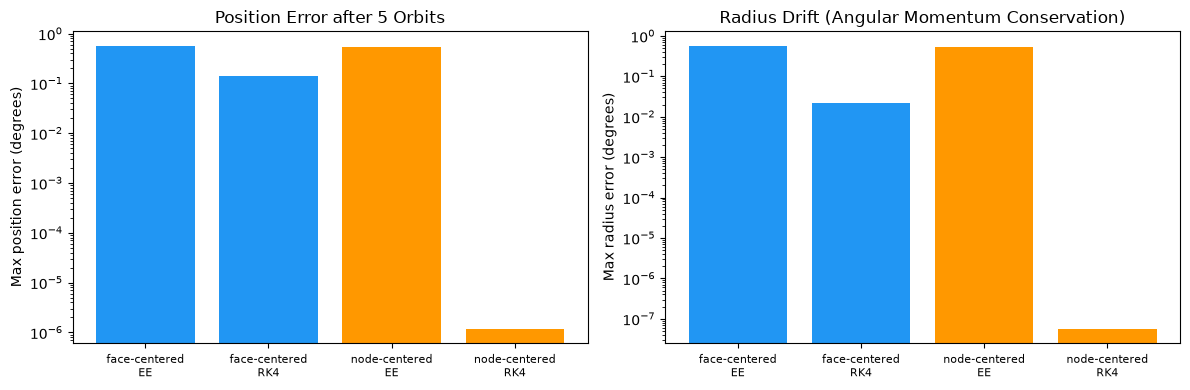

In [9]:
# Error bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = [f"{r['field_location']}\n{r['integrator']}" for r in results]
colors = ["#2196F3" if "face" in r["field_location"] else "#FF9800" for r in results]

# Position error
ax = axes[0]
ax.bar(range(len(results)), [r["max_position_error"] for r in results], color=colors)
ax.set_xticks(range(len(results)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Max position error (degrees)")
ax.set_title("Position Error after 5 Orbits")
ax.set_yscale("log")

# Radius error (angular momentum)
ax = axes[1]
ax.bar(range(len(results)), [r["max_radius_error"] for r in results], color=colors)
ax.set_xticks(range(len(results)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Max radius error (degrees)")
ax.set_title("Radius Drift (Angular Momentum Conservation)")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

## 7. Trajectory Visualization

Overlay computed trajectories (from parquet) against the analytical circular orbits.

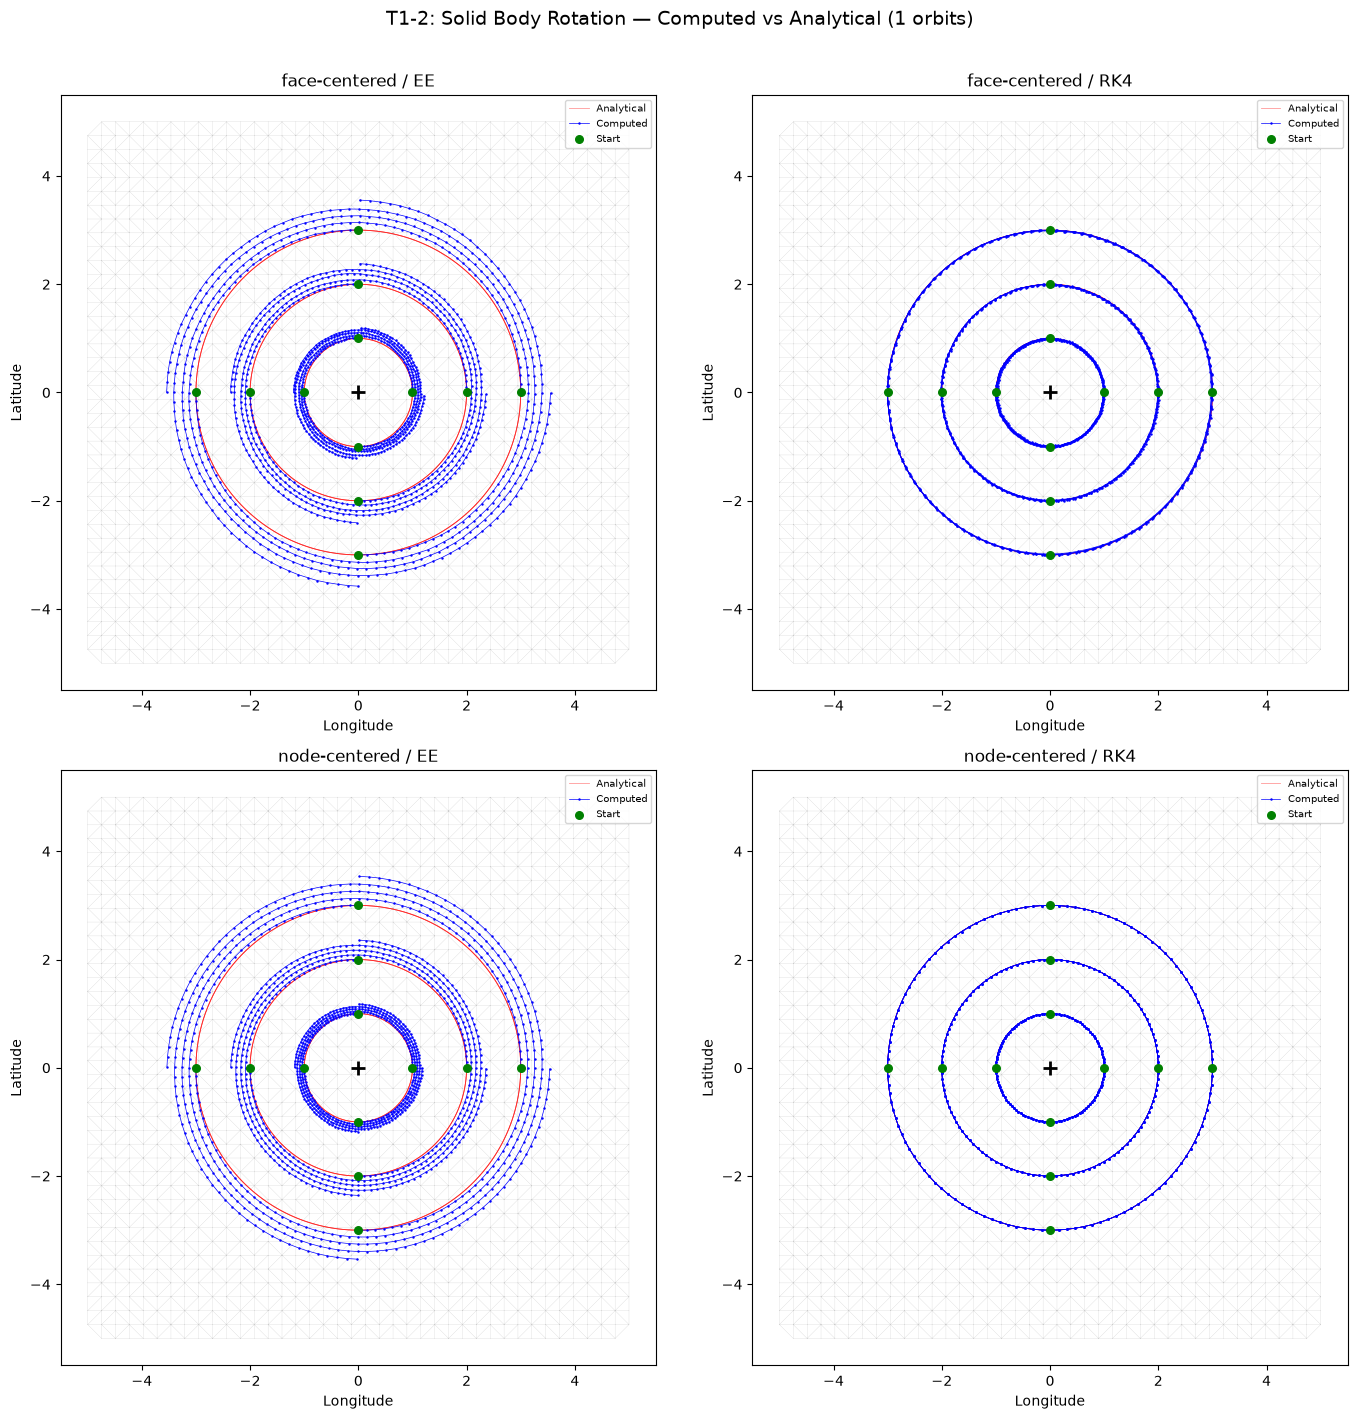

In [10]:
n_combos = len(output_files)
ncols = 2
nrows = math.ceil(n_combos / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 7 * nrows), squeeze=False)

# Analytical trajectory arcs
t_fine = np.linspace(0, T_TOTAL_S, 500)

for idx, (label, out_path) in enumerate(output_files.items()):
    ax = axes[idx // ncols, idx % ncols]

    # Grid
    ax.triplot(triang, "k-", lw=0.2, alpha=0.2)

    # Analytical circles
    for i in range(N_PARTICLES):
        xa, ya = analytical_trajectory(p_lon0[i], p_lat0[i], OMEGA, t_fine)
        ax.plot(xa, ya, "r-", lw=0.6, alpha=0.4,
                label="Analytical" if i == 0 else None)

    # Computed trajectories from the parquet particle file
    traj_df = parcels.read_particlefile(out_path).sort("particle_id", "t")
    for p, pid in enumerate(traj_df["particle_id"].unique().sort()):
        traj = traj_df.filter(traj_df["particle_id"] == pid)
        lons = traj["x"].to_numpy()
        lats = traj["y"].to_numpy()
        ax.plot(lons, lats, "b.-", ms=1.5, lw=0.5,
                label="Computed" if p == 0 else None)

    ax.scatter(p_lon0, p_lat0, c="green", s=30, zorder=5,
               label="Start")
    ax.plot(0, 0, "k+", ms=10, mew=2)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(label)
    ax.legend(fontsize=7, loc="upper right")
    ax.set_aspect("equal")

for idx in range(n_combos, nrows * ncols):
    axes[idx // ncols, idx % ncols].set_visible(False)

fig.suptitle(f"T1-2: Solid Body Rotation — Computed vs Analytical ({N_ORBITS} orbits)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 8. Convergence Study ($\Delta t$ refinement, node-centered)

On the node-centered grid the interpolant is exact for this linear field, so all error
comes from the time integrator. We refine $\Delta t$ and measure the slope:

- **Euler (EE):** expected slope $\approx 1$
- **RK4:** expected slope $\approx 4$

**Why Euler gets its own (smaller) $\Delta t$ range.** For solid-body rotation, one Euler step multiplies the
radius by exactly $\sqrt{1+(\Omega\Delta t)^2}$, so Euler particles spiral outwards. Over one orbit with
$\Delta t = 300$ s the R = 3 particles reach R ≈ 12.8 and with $\Delta t = 150$ s R ≈ 6.6 — outside the
$[-5,5]^2$ domain. The current Parcels raises `GridSearchingError` when a particle leaves the grid,
which crashed this cell. Euler therefore uses $\Delta t \le 60$ s (largest radius 4.2); RK4 stays on its
circle and keeps the original range. A `DeleteOutOfDomain` kernel is added as a guard: it deletes any particle
that still leaves the grid instead of crashing, and the cell reports how many were lost (expected: 0).

In [11]:
from parcels import StatusCode


def DeleteOutOfDomain(particles, fieldset):
    """Delete particles that left the grid (any error state) instead of raising GridSearchingError."""
    lost = particles.state >= StatusCode.Error
    particles[lost].state = StatusCode.Delete


# dt values for convergence study (seconds), per integrator (see the note above for Euler)
DT_VALUES = {
    "EE": [60, 30, 15, 10, 5],
    "RK4": [300, 150, 60, 30, 15],
}

# Run for just 1 orbit to keep it quick
T_CONV_S = PERIOD
T_CONV = np.timedelta64(int(T_CONV_S), "s")

convergence_results = []

fieldset_node = parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")

for integrator_label, integrator in time_integrators.items():
    for dt_s in DT_VALUES[integrator_label]:
        dt = np.timedelta64(dt_s, "s")

        pset = parcels.ParticleSet(
            fieldset_node,
            pclass=Particle64,
            x=p_lon0.copy(),
            y=p_lat0.copy(),
        )

        pset.execute(
            [integrator, DeleteOutOfDomain],
            runtime=T_CONV,
            dt=dt,
            verbose_progress=False,
        )

        # errors over the surviving particles (all of them, unless some left the domain)
        pid = np.asarray(pset.particle_id)
        lon_exact, lat_exact = analytical_position(p_lon0[pid], p_lat0[pid], OMEGA, T_CONV_S)
        pos_err = np.sqrt((pset.x - lon_exact)**2 + (pset.y - lat_exact)**2)
        n_lost = N_PARTICLES - len(pid)

        convergence_results.append({
            "integrator": integrator_label,
            "dt_s": dt_s,
            "max_error": np.max(pos_err),
            "mean_error": np.mean(pos_err),
            "n_lost": n_lost,
        })

        print(f"{integrator_label:4s} | dt={dt_s:4d}s | max err = {np.max(pos_err):.4e}"
              + (f"  ({n_lost} particles left the domain)" if n_lost else ""))

df_conv = pd.DataFrame(convergence_results)
df_conv

EE   | dt=  60s | max err = 1.1640e+00


EE   | dt=  30s | max err = 5.3592e-01


EE   | dt=  15s | max err = 2.5712e-01


EE   | dt=  10s | max err = 1.6907e-01


EE   | dt=   5s | max err = 8.3383e-02


...

RK4  | dt= 150s | max err = 7.3742e-04


RK4  | dt=  60s | max err = 1.8917e-05


RK4  | dt=  30s | max err = 1.1748e-06


RK4  | dt=  15s | max err = 8.5453e-08


,integrator,dt_s,max_error,mean_error,n_lost
0,EE,60,1.164015e+00,7.760101e-01,0
1,EE,30,5.359168e-01,3.572779e-01,0
2,EE,15,2.571182e-01,1.714122e-01,0
3,EE,10,1.690716e-01,1.127144e-01,0
4,EE,5,8.338270e-02,5.558847e-02,0
5,RK4,300,1.176530e-02,7.843529e-03,0
6,RK4,150,7.374176e-04,4.916011e-04,0
7,RK4,60,1.891700e-05,1.258843e-05,0
8,RK4,30,1.174843e-06,7.829420e-07,0
9,RK4,15,8.545341e-08,5.185579e-08,0


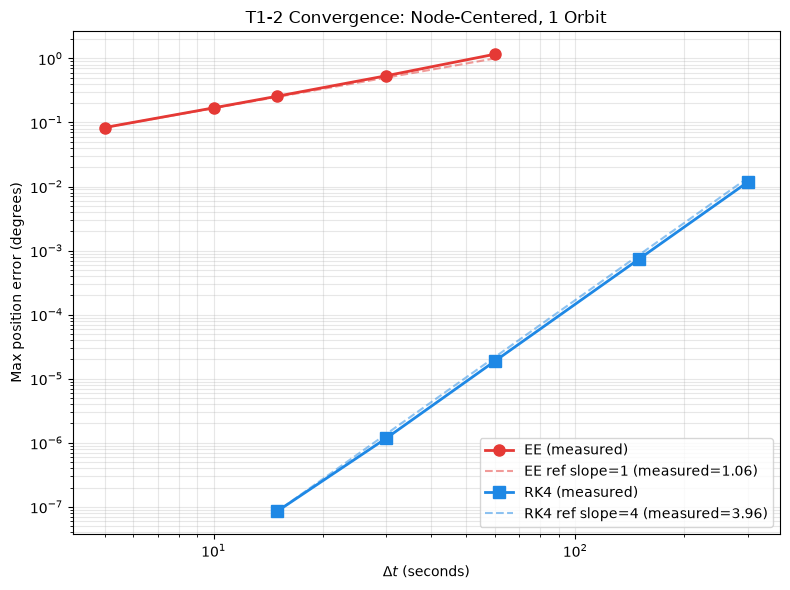

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

markers = {"EE": "o", "RK4": "s"}
colors_int = {"EE": "#E53935", "RK4": "#1E88E5"}
expected_orders = {"EE": 1, "RK4": 4}

for integrator_label in time_integrators:
    mask = df_conv["integrator"] == integrator_label
    dts = df_conv.loc[mask, "dt_s"].values.astype(float)
    errs = df_conv.loc[mask, "max_error"].values

    ax.loglog(dts, errs, f"{markers[integrator_label]}-",
              color=colors_int[integrator_label],
              label=f"{integrator_label} (measured)", ms=8, lw=2)

    # Compute observed slope via linear regression in log-log
    if len(dts) >= 2 and np.all(errs > 0):
        log_dt = np.log(dts)
        log_err = np.log(errs)
        slope = np.polyfit(log_dt, log_err, 1)[0]

        # Reference slope line
        p = expected_orders[integrator_label]
        ref_err = errs[-1] * (dts / dts[-1])**p
        ax.loglog(dts, ref_err, "--",
                  color=colors_int[integrator_label], alpha=0.5,
                  label=f"{integrator_label} ref slope={p} (measured={slope:.2f})")

ax.set_xlabel(r"$\Delta t$ (seconds)")
ax.set_ylabel("Max position error (degrees)")
ax.set_title(r"T1-2 Convergence: Node-Centered, 1 Orbit")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Period Error Over Many Orbits (Node-Centered)

Track how the position and radius errors grow orbit-by-orbit over 10 orbits.

- **RK4** is not symplectic, but at this $\Delta t$ its radius drift is tiny.
- **Euler** grows the radius by exactly $\sqrt{1+(\Omega\Delta t)^2}$ per step, i.e. by
  $\left(1+(\Omega\Delta t)^2\right)^{n/2}$ after $n$ steps. Since the interpolation is exact, the measured Euler radius
  must follow this formula — that is the check here (dashed line in the plot), not radius conservation.

$\Delta t = 5$ s keeps all Euler particles inside the domain for 10 orbits (R = 3 grows to 3.95). With the original
$\Delta t = 30$ s Euler grows the radius by a factor 1.18 per orbit and every particle has left the domain by orbit 10
(R = 3 reaches 15), which crashed this cell. The `DeleteOutOfDomain` guard is kept.

In [13]:
N_ORBITS_CHECK = 10
DT_ORBIT_CHECK_S = 5.0
DT_ORBIT_CHECK = np.timedelta64(int(DT_ORBIT_CHECK_S), "s")
STEPS_PER_ORBIT = int(round(PERIOD / DT_ORBIT_CHECK_S))
EE_GROWTH_PER_STEP = np.sqrt(1.0 + (OMEGA * DT_ORBIT_CHECK_S) ** 2)   # exact Euler radius factor per step

orbit_results = {label: {"orbit": [], "max_pos_err": [], "max_R_err": [], "max_R_vs_EE_theory": [],
                         "n_alive": []}
                 for label in time_integrators}

fieldset_node2 = parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")
R_exact = np.sqrt(p_lon0**2 + p_lat0**2)

for integrator_label, integrator in time_integrators.items():
    pset = parcels.ParticleSet(
        fieldset_node2,
        pclass=Particle64,
        x=p_lon0.copy(),
        y=p_lat0.copy(),
    )

    one_orbit = np.timedelta64(int(PERIOD), "s")

    for orb in range(1, N_ORBITS_CHECK + 1):
        pset.execute(
            [integrator, DeleteOutOfDomain],
            runtime=one_orbit,
            dt=DT_ORBIT_CHECK,
            verbose_progress=False,
        )
        if len(pset) == 0:
            print(f"{integrator_label}: all particles left the domain during orbit {orb}")
            break

        pid = np.asarray(pset.particle_id)
        t_elapsed = orb * PERIOD
        lon_exact, lat_exact = analytical_position(p_lon0[pid], p_lat0[pid], OMEGA, t_elapsed)
        pos_err = np.sqrt((pset.x - lon_exact)**2 + (pset.y - lat_exact)**2)
        R_now = np.sqrt(pset.x**2 + pset.y**2)
        R_ee_theory = R_exact[pid] * EE_GROWTH_PER_STEP ** (orb * STEPS_PER_ORBIT)

        orbit_results[integrator_label]["orbit"].append(orb)
        orbit_results[integrator_label]["max_pos_err"].append(np.max(pos_err))
        orbit_results[integrator_label]["max_R_err"].append(np.max(np.abs(R_now - R_exact[pid])))
        orbit_results[integrator_label]["max_R_vs_EE_theory"].append(np.max(np.abs(R_now / R_ee_theory - 1)))
        orbit_results[integrator_label]["n_alive"].append(len(pid))

    print(f"{integrator_label}: final orbit {orbit_results[integrator_label]['orbit'][-1]} — "
          f"max pos err = {orbit_results[integrator_label]['max_pos_err'][-1]:.4e}, "
          f"max R err = {orbit_results[integrator_label]['max_R_err'][-1]:.4e}, "
          f"particles in domain = {orbit_results[integrator_label]['n_alive'][-1]}/{N_PARTICLES}")

EE: final orbit 10 — max pos err = 9.4623e-01, max R err = 9.4622e-01, particles in domain = 12/12


RK4: final orbit 10 — max pos err = 1.6715e-07, max R err = 1.3111e-07, particles in domain = 12/12


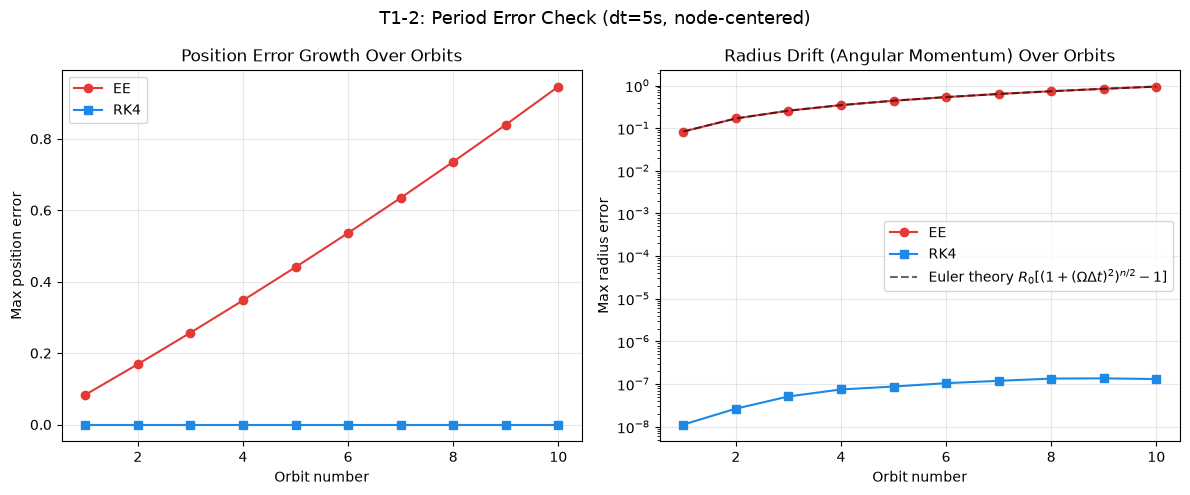

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for integrator_label in time_integrators:
    data = orbit_results[integrator_label]
    axes[0].plot(data["orbit"], data["max_pos_err"],
                f"{markers[integrator_label]}-",
                color=colors_int[integrator_label],
                label=integrator_label, ms=6)
    axes[1].plot(data["orbit"], data["max_R_err"],
                f"{markers[integrator_label]}-",
                color=colors_int[integrator_label],
                label=integrator_label, ms=6)

axes[0].set_xlabel("Orbit number")
axes[0].set_ylabel("Max position error")
axes[0].set_title("Position Error Growth Over Orbits")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

orbits = np.arange(1, N_ORBITS_CHECK + 1)
axes[1].plot(orbits, np.max(R_exact) * (EE_GROWTH_PER_STEP ** (orbits * STEPS_PER_ORBIT) - 1), "k--", alpha=0.6,
             label=r"Euler theory $R_0[(1+(\Omega\Delta t)^2)^{n/2}-1]$")
axes[1].set_yscale("log")
axes[1].set_xlabel("Orbit number")
axes[1].set_ylabel("Max radius error")
axes[1].set_title("Radius Drift (Angular Momentum) Over Orbits")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle(f"T1-2: Period Error Check (dt={DT_ORBIT_CHECK_S:.0f}s, node-centered)",
             fontsize=13)
plt.tight_layout()
plt.show()

## 10. Verification Assertions

### Node-centered checks
With exact interpolation of the linear field, all error is from the ODE integrator:
1. **Convergence order:** measured slope should be within 0.5 of the expected order
2. **RK4 at fine dt:** error should be very small (< 1e-6 after 1 orbit)

### Face-centered checks
Piecewise-constant interpolation introduces spatial error, so we only check that
the simulation completes and the particle stays within a reasonable bound.

In [15]:
all_pass = True

# --- Check 1: Convergence orders (node-centered) ---
print("=== Convergence Order Checks (node-centered) ===")
for integrator_label in time_integrators:
    mask = df_conv["integrator"] == integrator_label
    dts = df_conv.loc[mask, "dt_s"].values.astype(float)
    errs = df_conv.loc[mask, "max_error"].values

    if len(dts) >= 2 and np.all(errs > 0):
        slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
        expected = expected_orders[integrator_label]
        ok = abs(slope - expected) < 0.5
        status = "PASS" if ok else "FAIL"
        if not ok:
            all_pass = False
        print(f"  [{status}] {integrator_label}: measured slope = {slope:.2f}, "
              f"expected ~ {expected}")
    else:
        print(f"  [SKIP] {integrator_label}: insufficient data for slope")

# --- Check 2: RK4 absolute accuracy at finest dt ---
print("\n=== RK4 Absolute Accuracy (node-centered, finest dt) ===")
rk4_finest = df_conv.loc[
    (df_conv["integrator"] == "RK4") & (df_conv["dt_s"] == min(DT_VALUES["RK4"])),
    "max_error"
].values
if len(rk4_finest) > 0:
    err = rk4_finest[0]
    ok = err < 1e-6
    status = "PASS" if ok else "FAIL"
    if not ok:
        all_pass = False
    print(f"  [{status}] RK4 max error at dt={min(DT_VALUES['RK4'])}s: {err:.4e} (threshold 1e-6)")

# --- Check 3: Radius behaviour over many orbits ---
print("\n=== Radius Over Orbits (node-centered) ===")
# RK4: radius must stay (nearly) conserved
final_R_err = orbit_results["RK4"]["max_R_err"][-1]
ok = final_R_err < 0.1  # generous bound
all_pass &= ok
print(f"  [{'PASS' if ok else 'FAIL'}] RK4: max radius drift after {N_ORBITS_CHECK} orbits = {final_R_err:.4e} (< 0.1)")
# Euler: radius must follow the exact Euler growth (1 + (Omega dt)^2)^(n/2); exact interpolation ->
# only Parcels' float32 barycentric weights (~1e-8 relative) separate them
ee_dev = max(orbit_results["EE"]["max_R_vs_EE_theory"])
ok = ee_dev < 1e-6
all_pass &= ok
print(f"  [{'PASS' if ok else 'FAIL'}] EE: max |R / R_Euler_theory - 1| over {N_ORBITS_CHECK} orbits = {ee_dev:.2e} (< 1e-6)")
# no particle may have left the domain in the convergence or orbit runs
n_lost_total = int(df_conv["n_lost"].sum()) + sum(N_PARTICLES - orbit_results[k]["n_alive"][-1] for k in orbit_results)
ok = n_lost_total == 0
all_pass &= ok
print(f"  [{'PASS' if ok else 'FAIL'}] particles lost from the domain in sections 8-9: {n_lost_total}")

# --- Check 4: Face-centered runs complete with bounded error ---
print("\n=== Face-Centered Sanity Checks ===")
for r in results:
    if r["field_location"] == "face-centered":
        ok = r["max_position_error"] < 5.0  # generous: spatial error dominates
        status = "PASS" if ok else "FAIL"
        if not ok:
            all_pass = False
        print(f"  [{status}] {r['field_location']} / {r['integrator']}: "
              f"max err = {r['max_position_error']:.4e}")

print()
if all_pass:
    print("T1-2 PASSED: All checks within tolerance.")
else:
    raise AssertionError(
        "T1-2 FAILED: One or more checks exceeded tolerance. "
        "Review convergence plots above."
    )

=== Convergence Order Checks (node-centered) ===


  [PASS] EE: measured slope = 1.06, expected ~ 1
  [PASS] RK4: measured slope = 3.96, expected ~ 4

=== RK4 Absolute Accuracy (node-centered, finest dt) ===
  [PASS] RK4 max error at dt=15s: 8.5453e-08 (threshold 1e-6)

=== Radius Over Orbits (node-centered) ===
  [PASS] RK4: max radius drift after 10 orbits = 1.3111e-07 (< 0.1)
  [PASS] EE: max |R / R_Euler_theory - 1| over 10 orbits = 1.62e-08 (< 1e-6)
  [PASS] particles lost from the domain in sections 8-9: 0

=== Face-Centered Sanity Checks ===
  [PASS] face-centered / EE: max err = 5.7732e-01
  [PASS] face-centered / RK4: max err = 1.4279e-01

T1-2 PASSED: All checks within tolerance.


## 11. Cleanup

In [16]:
for out_path in output_files.values():
    if os.path.exists(out_path):
        os.remove(out_path)
print("Temporary output cleaned up.")

Temporary output cleaned up.
